# 03 — What changed between December 2025 and September 2026?

Notebooks 01–02 looked at one Barcelona snapshot. Here: **four quarterly
Barcelona snapshots** (Dec 2025, Mar, Jun, Sep 2026) and the same months in
**Madrid, Valencia, Málaga and Sevilla**.

Why the other cities matter: on **1 January 2026** Catalonia extended its rent
limit to seasonal lets (Llei 11/2025, see `POLICY_LEVERS`). That law does not
apply in Madrid, Valencia or Andalucía. If something changes in Barcelona
*and not elsewhere*, timing points at a Catalan cause; if it changes
everywhere, it does not. This is a comparison, not an experiment — the cities
differ in many other ways, and a single Barcelona snapshot before January
cannot establish a common trend.

**One population for every snapshot:** *listings with open dates* (at least
one open date in the next 365 days). An empty calendar can mean booked,
blocked or withdrawn, so the rest are "listed, no open dates". A listing that
is absent from a later scrape may have been withdrawn, re-listed under a new
id, or missed by the scrape. See `data/README.md`.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src import config as cfg
from src import cleaning, metrics
from src import sources as src

sns.set_theme(style="whitegrid", palette="colorblind")

snapshots = {
    (city, date): cleaning.add_columns(cleaning.load_snapshot(city, date))
    for city, dates in src.SNAPSHOTS.items()
    for date in dates
}
print(f"{len(snapshots)} snapshots loaded")

12 snapshots loaded


## The headline numbers, every city and snapshot

`share_month_plus` = listings with open dates asking **31 nights or more**. It
is used for cross-city comparison as a common measurement threshold, not as a
legal rule: the legal lines differ between regions.

In [2]:
summary = pd.DataFrame([
    {"city": city, "snapshot": date, **metrics.snapshot_summary(df),
     "top_1pct_hosts": metrics.top_host_share(df, 1)}
    for (city, date), df in snapshots.items()
]).set_index(["city", "snapshot"])
summary

population  listings  active  \
city      snapshot                                                 
barcelona 2025-12-14  listings with open dates     18177   15592   
          2026-03-21  listings with open dates     16107   13328   
          2026-06-24  listings with open dates     15406   14017   
          2026-09-17  listings with open dates     15236   11737   
madrid    2025-12-14  listings with open dates     24616   19830   
          2026-09-17  listings with open dates     23109   17561   
valencia  2025-12-27  listings with open dates      7702    7219   
          2026-09-20  listings with open dates      7968    6236   
malaga    2025-12-31  listings with open dates      8811    8728   
          2026-09-28  listings with open dates      9505    7385   
sevilla   2025-12-30  listings with open dates      7674    7561   
          2026-09-25  listings with open dates      8375    6474   

                                                                 counts  \
city      snapshot                                                        
barcelona 2025-12-14  {'share_31_nights': [2936, 15592], 'share_mont...   
          2026-03-21  {'share_31_nights': [2340, 13328], 'share_mont...   
          2026-06-24  {'share_31_nights': [2463, 14017], 'share_mont...   
          2026-09-17  {'share_31_nights': [2293, 11737], 'share_mont...   
madrid    2025-12-14  {'share_31_nights': [966, 19830], 'share_month...   
          2026-09-17  {'share_31_nights': [812, 17561], 'share_month...   
valencia  2025-12-27  {'share_31_nights': [45, 7219], 'share_month_p...   
          2026-09-20  {'share_31_nights': [57, 6236], 'share_month_p...   
malaga    2025-12-31  {'share_31_nights': [14, 8728], 'share_month_p...   
          2026-09-28  {'share_31_nights': [4, 7385], 'share_month_pl...   
sevilla   2025-12-30  {'share_31_nights': [5, 7561], 'share_month_pl...   
          2026-09-25  {'share_31_nights': [4, 6474], 'share_month_pl...   

                      share_31_nights  share_month_plus  \
city      snapshot                                        
barcelona 2025-12-14             18.8              42.0   
          2026-03-21             17.6              34.7   
          2026-06-24             17.6              37.1   
          2026-09-17             19.5              41.7   
madrid    2025-12-14              4.9               8.5   
          2026-09-17              4.6               7.8   
valencia  2025-12-27              0.6               2.1   
          2026-09-20              0.9               2.0   
malaga    2025-12-31              0.2               2.1   
          2026-09-28              0.1               2.3   
sevilla   2025-12-30              0.1               1.7   
          2026-09-25              0.1               2.4   

                      share_tourist_licence  share_nrua_seasonal  \
city      snapshot                                                 
barcelona 2025-12-14                   36.0                 15.5   
          2026-03-21                   47.7                 20.5   
          2026-06-24                   51.0                 24.6   
          2026-09-17                   45.4                 21.6   
madrid    2025-12-14                    6.7                 31.1   
          2026-09-17                    9.4                 39.1   
valencia  2025-12-27                   27.8                 18.8   
          2026-09-20                   38.8                 25.8   
malaga    2025-12-31                   55.6                  1.3   
          2026-09-28                   73.8                  1.3   
sevilla   2025-12-30                   54.5                  0.6   
          2026-09-25                   72.2                  1.2   

                      share_professional  share_entire_home  median_price  \
city      snapshot                                                          
barcelona 2025-12-14                68.1               71.0           NaN   
          2026-03-21 

Dec 2025 prices are empty in every city (an Inside Airbnb gap), so
`median_price` starts in 2026.

## Barcelona, quarter by quarter

,under_31,exactly_31,over_31
2025-12-14,9045,2936,3611
2026-03-21,8707,2340,2281
2026-06-24,8813,2463,2741
2026-09-17,6848,2293,2596


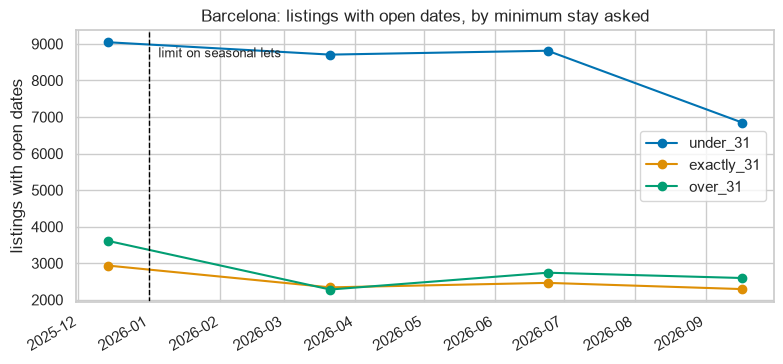

In [3]:
bcn = pd.DataFrame({
    date: metrics.band_counts(snapshots[("barcelona", date)])
    for date in src.SNAPSHOTS["barcelona"]
}).T
bcn.index = pd.to_datetime(bcn.index)

fig, ax = plt.subplots(figsize=(9, 4))
bcn.plot(ax=ax, marker="o")
ax.axvline(pd.Timestamp(cfg.POLICY_LEVERS["seasonal_rentals"]["applies_from"]),
           color="black", ls="--", lw=1)
ax.text(pd.Timestamp("2026-01-05"), ax.get_ylim()[1] * 0.92, "limit on seasonal lets", fontsize=9)
ax.set_ylabel("listings with open dates"); ax.set_xlabel("")
ax.set_title("Barcelona: listings with open dates, by minimum stay asked")
fig.savefig(cfg.FIGURES_DIR / "03_barcelona_bands.png", dpi=150, bbox_inches="tight")
bcn

Between December and March the over-31 group shrank by about a third
and the exactly-31 group by a fifth, while the under-31 group barely moved. By
September both had partly recovered.

The under-31 group's drop in **September** is a different story: it coincides
with the jump in listings with no open dates that hits *every* city in the
September snapshots (see `data/README.md`), so it is not read as a Barcelona
effect.

**What this cannot show:** a snapshot count mixes listings leaving, new
listings arriving and hosts changing their minimum stay. The next section
separates those by following each listing's id.

## Where did December's listings go?

Inside Airbnb keeps the same listing id across snapshots, so each December
listing with open dates can be followed to September: same group, a different
group, still listed but with no open dates (*inactive*), or absent from the
later scrape (*gone*).

In [4]:
def transition_shares(city):
    dates = src.SNAPSHOTS[city]
    table = metrics.transitions(snapshots[(city, dates[0])], snapshots[(city, dates[-1])])
    return table, (table.div(table.sum(axis=1), axis=0) * 100).round(1)

bcn_table, bcn_shares = transition_shares("barcelona")
mad_table, mad_shares = transition_shares("madrid")
print("Barcelona, Dec 2025 -> Sep 2026 (% of each December group):")
print(bcn_shares.to_string())
print()
print("Madrid, same months:")
print(mad_shares.to_string())

Barcelona, Dec 2025 -> Sep 2026 (% of each December group):
stay_band   under_31  exactly_31  over_31  inactive  gone
stay_band                                                
under_31        57.9         1.1      2.3      16.5  22.1
exactly_31       1.8        43.7      4.3      11.0  39.2
over_31          3.2         3.9     49.5       5.7  37.7

Madrid, same months:
stay_band   under_31  exactly_31  over_31  inactive  gone
stay_band                                                
under_31        64.1         0.3      0.4      13.0  22.2
exactly_31       8.6        51.9      1.9      10.2  27.4
over_31         28.7         1.7     39.0      10.6  20.0


In Barcelona, December's over-31 and exactly-31 listings were much more
likely to be **absent from the September scrape** than its under-31 listings.
In Madrid the exit rates are closer across groups.

Listings that are absent may have been withdrawn, moved to other platforms,
switched to long-term leases, sold, re-listed under a new id or missed by the
scrape — the file cannot tell which.

## The exit gap, with uncertainty that allows for host accounts

- **Exit gap** = (share of month-plus listings absent from the September
  scrape) − (the same share for listings asking under 31 nights). Month-plus =
  asking 31 or more nights, the same threshold in every city.
- **Why not a simple z-test?** One host account can withdraw many listings at
  once, so listings are not independent. The interval below resamples whole
  **host accounts** (3,000 bootstrap draws, one seed per city), which keeps
  that dependence. It is a sensitivity estimate of sampling variation only: it
  does not cover scrape omissions, platform changes or confounding, and it is
  not an estimate of any rule's effect.
- To compare two cities, the quantity to test is their **difference** (Barcelona
  minus the other city), not whether two separate intervals overlap.

In [5]:
draws, accounts = {}, {}
for index, (city, dates) in enumerate(src.SNAPSHOTS.items()):
    earlier, later = snapshots[(city, dates[0])], snapshots[(city, dates[-1])]
    accounts[city] = metrics.exit_gap_cohort(earlier, later)
    draws[city] = metrics.exit_gap_draws(accounts[city], seed=cfg.SEED + index)

rows = []
for city, dates in src.SNAPSHOTS.items():
    earlier, later = snapshots[(city, dates[0])], snapshots[(city, dates[-1])]
    gap, se = metrics.exit_gap(metrics.transitions(earlier, later))
    low, high = metrics.percentile_interval(draws[city])
    rows.append({
        "city": city,
        "host_accounts": len(accounts[city]),
        "month_plus_listings": int(accounts[city]["month_n"].sum()),
        "shorter_listings": int(accounts[city]["short_n"].sum()),
        "top10_accounts_share_of_month_plus_%": metrics.top_account_share(accounts[city]),
        "exit_gap_points": round(gap, 1),
        "ci_low (accounts resampled)": low,
        "ci_high (accounts resampled)": high,
        "listing-level ci (too narrow)": f"[{gap - 1.96 * se:.1f}, {gap + 1.96 * se:.1f}]",
    })
pd.DataFrame(rows).set_index("city")

,host_accounts,month_plus_listings,shorter_listings,top10_accounts_share_of_month_plus_%,exit_gap_points,ci_low (accounts resampled),ci_high (accounts resampled),listing-level ci (too narrow)
city,,,,,,,,
barcelona,4016,6547,9045,30.6,16.3,6.2,26.6,"[14.9, 17.8]"
madrid,6948,1691,18139,57.5,2.1,-12.5,25.0,"[-0.1, 4.2]"
valencia,3231,152,7067,40.8,12.1,-4.2,28.6,"[4.8, 19.4]"
malaga,3299,182,8546,50.5,21.1,8.9,35.3,"[14.1, 28.0]"
sevilla,2974,132,7429,28.8,15.5,5.4,26.4,"[8.0, 23.0]"


Three things stand out:

- Barcelona, Málaga and Sevilla have intervals **above zero**; Madrid and
  Valencia include zero.
- The account-level intervals are **several times wider** than the listing-level
  ones. Month-plus listings are held by few accounts: the 10 largest accounts
  hold 31% of Barcelona's month-plus listings and 58% of Madrid's.
- Valencia, Málaga and Sevilla have only 130–180 month-plus listings each, so
  their estimates are rough.

In [6]:
point = {r["city"]: r["exit_gap_points"] for r in rows}
contrasts = []
for city in ["madrid", "valencia", "malaga", "sevilla"]:
    difference = metrics.contrast_draws(draws["barcelona"], draws[city])
    low, high = metrics.percentile_interval(difference)
    contrasts.append({
        "barcelona_minus": city,
        "difference_points": round(point["barcelona"] - point[city], 1),
        "ci_low": low, "ci_high": high,
        "interval_includes_zero": bool(low <= 0 <= high),
    })
pd.DataFrame(contrasts).set_index("barcelona_minus")

,difference_points,ci_low,ci_high,interval_includes_zero
barcelona_minus,,,,
madrid,14.2,-10.2,32.9,True
valencia,4.2,-15.5,23.3,True
malaga,-4.8,-21.9,11.4,True
sevilla,0.8,-13.1,15.0,True


**Every contrast includes zero.** The data cannot distinguish Barcelona's
exit gap from any of the four other cities' gaps: not from Madrid's, not from
the cities where the Catalan law does not apply. So the evidence does **not**
single out the Catalan seasonal-rent limit as the reason month-plus listings
left the scrape, and it does not rule an effect out either.

**A correction.** An earlier version of this notebook ran a z-test on the
difference between Barcelona's and Madrid's gaps and reported +14.3 points with
p ≈ 10⁻²⁷, then concluded that "Madrid is the outlier". That test treated
listings as independent. With host accounts resampled, the same difference is
+14.2 points with an interval of about −10 to +33. The earlier result came from
the independence assumption, not from the data, and it is withdrawn.

What *is* specific to Barcelona is the **size** of its month-plus segment
(~42% of listings with open dates, vs 2–8% elsewhere) and the dip in the
over-31 group between December and March. The other cities have no March
snapshot, so that dip cannot be compared — and without a previous year it
cannot be separated from an ordinary winter pattern either.

## Licence display rose everywhere

If one city's licence share rose because of a local rule, the others should
stay flat. They did not:

In [7]:
# Snapshot dates differ by a few days between cities: label by round
first_last = {city: {"Dec 2025": dates[0], "Sep 2026": dates[-1]} for city, dates in src.SNAPSHOTS.items()}
licence = pd.DataFrame({
    city: {label: summary.loc[(city, date), "share_tourist_licence"] for label, date in rounds.items()}
    for city, rounds in first_last.items()
}).T
licence.assign(change=licence["Sep 2026"] - licence["Dec 2025"])

,Dec 2025,Sep 2026,change
barcelona,36.0,45.4,9.4
madrid,6.7,9.4,2.7
valencia,27.8,38.8,11.0
malaga,55.6,73.8,18.2
sevilla,54.5,72.2,17.7


Every city shows more listings with a regional tourist-flat number in
September than in December. That points at something national or
platform-wide rather than a Catalan rule.
Outside Catalonia these shares are a lower bound (see `data/README.md`).

**Airbnb's licence form changed.** The *Exempt – seasonal rental* option
appears between the March and June 2026 snapshots in Barcelona (0 to 2,881
listings with open dates) and is used in Madrid (6,833) and Valencia (1,450) by
September, but almost never in Málaga (4) or Sevilla (0). Licence fields are
left empty less often by September in every city:

In [8]:
form = pd.DataFrame({
    (city, date): {
        "no_licence_text": int(df.loc[df["is_active"], "license"].isna().sum()),
        "declared_seasonal": int((metrics.active(df)["regional_licence"] == "exempt_seasonal").sum()),
    }
    for (city, date), df in snapshots.items()
}).T
form

no_licence_text  declared_seasonal
barcelona 2025-12-14             5078                  0
          2026-03-21             2663                  0
          2026-06-24             2123               2881
          2026-09-17             2394               2572
madrid    2025-12-14             9561                  0
          2026-09-17             6081               6833
valencia  2025-12-27             2222                  0
          2026-09-20             1377               1450
malaga    2025-12-31              982                  0
          2026-09-28              563                  4
sevilla   2025-12-30              709                  0
          2026-09-25              498                  0

So part of the rise may be the platform asking more, not hosts changing.
Licence categories are **not comparable across the June 2026 change**:
the notebooks compare them within a snapshot, never as a before/after
effect of a rule.

## Who supplies the market? Concentration in each city

A host account (`host_id`) is not necessarily one owner or one company.

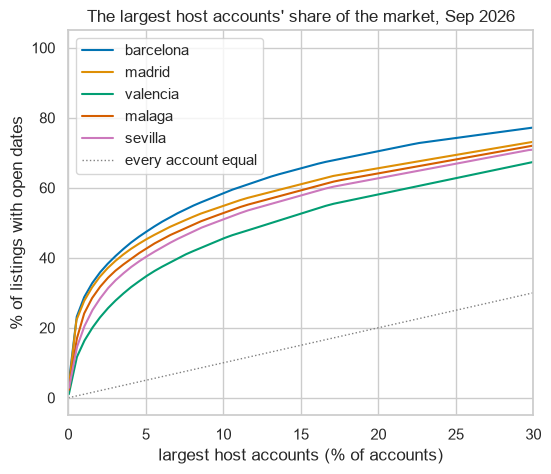

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
for city, dates in src.SNAPSHOTS.items():
    curve = metrics.concentration_curve(snapshots[(city, dates[-1])], points=200)
    ax.plot(curve["host_share"], curve["listing_share"], label=city)
ax.plot([0, 100], [0, 100], color="grey", ls=":", lw=1, label="every account equal")
ax.set_xlim(0, 30)
ax.set_xlabel("largest host accounts (% of accounts)"); ax.set_ylabel("% of listings with open dates")
ax.set_title("The largest host accounts' share of the market, Sep 2026")
ax.legend()
fig.savefig(cfg.FIGURES_DIR / "03_concentration.png", dpi=150, bbox_inches="tight")

## What I found

1. **Barcelona's month-plus segment is unique in size.** 41.7% of listings
   with open dates ask 31+ nights in September (42.0% in December), against
   7.8–8.5% in Madrid and about 2% in Valencia, Málaga and Sevilla.
2. **The over-31 group dipped after 1 January 2026.** Listings asking over 31
   nights went from 3,611 (Dec) to 2,281 (Mar) and 2,596 (Sep). With no March
   snapshot elsewhere and no previous year, the dip cannot be separated from
   a seasonal pattern.
3. **Month-plus listings were more likely than shorter-stay ones to be absent
   from the September scrape in Barcelona:** +16.3 points, 95% interval 6.2
   to 26.6 with host accounts resampled. Málaga (+21.1, [8.9, 35.3]) and
   Sevilla (+15.5, [5.4, 26.4]) are also above zero; Madrid (+2.1, [−12.5,
   25.0]) and Valencia (+12.1, [−4.2, 28.6]) include zero.
4. **No city's gap can be told apart from Barcelona's.** Barcelona minus
   each other city: Madrid +14.2 [−10.2, 32.9], Valencia +4.2 [−15.5, 23.3],
   Málaga −4.8 [−21.9, 11.4], Sevilla +0.8 [−13.1, 15.0]. Every interval
   includes zero, so the data does not single out the Catalan seasonal-rent
   limit, and does not rule an effect out. An earlier z-test that reported a
   Barcelona–Madrid difference with p ≈ 10⁻²⁷ treated listings as
   independent and is withdrawn.
5. **Licence display rose in every city** (+2.7 to +18.2 points). Airbnb's
   licence form changed too: the *Exempt – seasonal rental* option appears in
   Barcelona between March and June 2026 and is used in Madrid and Valencia
   by September, but almost never in Málaga or Sevilla, so the rise is not
   read as an effect of any rule.
6. **Supply is concentrated.** The largest 1% of host accounts run 29% of
   Barcelona's listings with open dates (Madrid 28%, Valencia 16%). In Madrid
   the 10 largest accounts hold 58% of the month-plus listings, which is why
   Madrid's interval is so wide.


**Next:** `04_register_and_rents.ipynb` — the official licence register
against the listings, and what official rents did over the same months.